## Import Microsoft data set

In [2]:

import pandas as pd
from pathlib import Path

# Dataset location relative to the notebook
data_path = Path("../data/raw/msft.us.txt")

# Load Microsoft historical stock prices
df = pd.read_csv(data_path)

# Display the first five records
df.head()


,Date,Open,High,Low,Close,Volume,OpenInt
0,1986-03-13,0.06720,0.07533,0.06720,0.07533,1371330506,0
1,1986-03-14,0.07533,0.07533,0.07533,0.07533,409569463,0
2,1986-03-17,0.07533,0.07533,0.07533,0.07533,176995245,0
3,1986-03-18,0.07533,0.07533,0.07533,0.07533,90067008,0
4,1986-03-19,0.07533,0.07533,0.07533,0.07533,63655515,0


## Inspect datatypes

In [3]:

# Inspect dataset structure
print("Dataset shape:", df.shape)

print("\nColumn data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nSummary statistics:")
display(df.describe())


Dataset shape: (7983, 7)

Column data types:
Date           str
Open       float64
High       float64
Low        float64
Close      float64
Volume       int64
OpenInt      int64
dtype: object

Missing values:
Date       0
Open       0
High       0
Low        0
Close      0
Volume     0
OpenInt    0
dtype: int64

Summary statistics:


,Open,High,Low,Close,Volume,OpenInt
count,7983.000000,7983.000000,7983.000000,7983.000000,7.983000e+03,7983.0
mean,18.977859,19.187219,18.773635,18.984698,7.945800e+07,0.0
std,16.416068,16.552604,16.277882,16.424012,5.214889e+07,0.0
min,0.067200,0.067200,0.067200,0.067200,0.000000e+00,0.0
25%,2.113300,2.155100,2.079700,2.113300,4.910587e+07,0.0
50%,20.462000,20.697000,20.251000,20.469000,7.059385e+07,0.0
75%,25.475000,25.754000,25.233000,25.483500,9.734927e+07,0.0
max,84.770000,86.200000,84.082500,84.560000,1.371331e+09,0.0


## Data preprocessing and sorting

In [4]:

# Convert Date to datetime
df["Date"] = pd.to_datetime(df["Date"])

# Sort chronologically
df = df.sort_values("Date").reset_index(drop=True)

# Remove OpenInt (constant zero)
df = df.drop(columns=["OpenInt"])

# Check for duplicate dates
print("Duplicate dates:", df["Date"].duplicated().sum())

# Check for zero-volume records
print("Zero-volume records:", (df["Volume"] == 0).sum())

# Check date range
print("First trading day:", df["Date"].min())
print("Last trading day:", df["Date"].max())

# Verify updated structure
print("\nUpdated DataFrame:")
df.info()


Duplicate dates: 0
Zero-volume records: 1
First trading day: 1986-03-13 00:00:00
Last trading day: 2017-11-10 00:00:00

Updated DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 7983 entries, 0 to 7982
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    7983 non-null   datetime64[us]
 1   Open    7983 non-null   float64       
 2   High    7983 non-null   float64       
 3   Low     7983 non-null   float64       
 4   Close   7983 non-null   float64       
 5   Volume  7983 non-null   int64         
dtypes: datetime64[us](1), float64(4), int64(1)
memory usage: 374.3 KB


In [5]:

# Inspect records with zero trading volume
zero_volume = df[df["Volume"] == 0]

display(zero_volume)


,Date,Open,High,Low,Close,Volume
6080,2010-04-26,25.997,26.223,25.886,26.088,0


In [6]:

import numpy as np

# Treat zero trading volume as missing
df["Volume"] = df["Volume"].replace(0, np.nan)

# Fill missing volume using the previous trading day
df["Volume"] = df["Volume"].ffill()

# Verify the correction
print("Missing volume values:", df["Volume"].isna().sum())
print("Zero-volume records:", (df["Volume"] == 0).sum())

# Inspect corrected record
display(df.loc[6079:6081])


Missing volume values: 0
Zero-volume records: 0


,Date,Open,High,Low,Close,Volume
6079,2010-04-23,26.088,26.482,25.703,25.963,151124535.0
6080,2010-04-26,25.997,26.223,25.886,26.088,151124535.0
6081,2010-04-27,25.945,26.205,25.785,25.862,81952417.0


## Visualize data

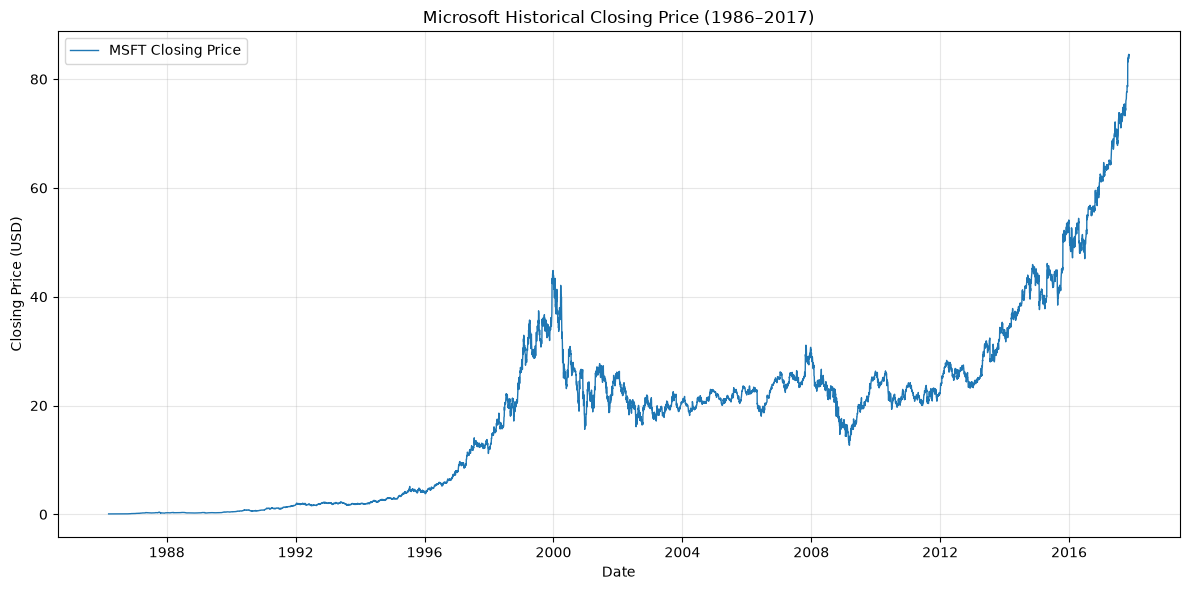

In [7]:

import matplotlib.pyplot as plt

# Plot Microsoft's historical closing price
plt.figure(figsize=(12, 6))

plt.plot(
    df["Date"],
    df["Close"],
    label="MSFT Closing Price",
    linewidth=1
)

plt.title("Microsoft Historical Closing Price (1986–2017)")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Daily return analysis

In [8]:

# Calculate daily percentage returns
df["Daily_Return"] = df["Close"].pct_change()

# Inspect the new feature
display(df[["Date", "Close", "Daily_Return"]].head(10))

# Summarize daily returns
print("Daily return statistics:")
display(df["Daily_Return"].describe())


,Date,Close,Daily_Return
0,1986-03-13,0.07533,NaN
1,1986-03-14,0.07533,0.000000
2,1986-03-17,0.07533,0.000000
3,1986-03-18,0.07533,0.000000
4,1986-03-19,0.07533,0.000000
5,1986-03-20,0.07533,0.000000
6,1986-03-21,0.06720,-0.107925
7,1986-03-24,0.06720,0.000000
8,1986-03-25,0.06720,0.000000
9,1986-03-26,0.06720,0.000000


Daily return statistics:


count    7982.000000
mean        0.001142
std         0.022892
min        -0.300080
25%        -0.008926
50%         0.000000
75%         0.010837
max         0.195347
Name: Daily_Return, dtype: float64

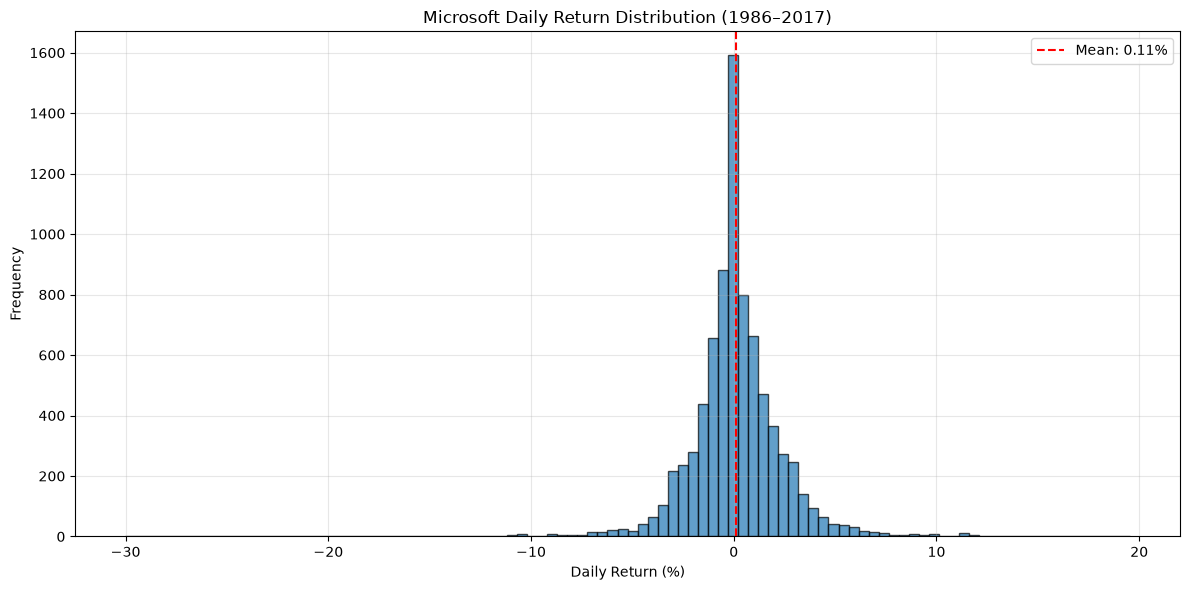

In [9]:

import matplotlib.pyplot as plt

# Convert daily returns to percentages for visualization
daily_returns = df["Daily_Return"].dropna() * 100

plt.figure(figsize=(12, 6))

plt.hist(
    daily_returns,
    bins=100,
    edgecolor="black",
    alpha=0.7
)

plt.axvline(
    daily_returns.mean(),
    color="red",
    linestyle="--",
    label=f"Mean: {daily_returns.mean():.2f}%"
)

plt.title("Microsoft Daily Return Distribution (1986–2017)")
plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [11]:

# Five largest positive daily returns
print("Largest positive daily returns:")
display(
    df.nlargest(5, "Daily_Return")[
        ["Date", "Close", "Volume", "Daily_Return"]
    ]
)

# Five largest negative daily returns
print("Largest negative daily returns:")
display(
    df.nsmallest(5, "Daily_Return")[
        ["Date", "Close", "Volume", "Daily_Return"]
    ]
)

# Count days with unchanged closing prices
unchanged_days = (df["Daily_Return"] == 0).sum()

print(f"\nDays with unchanged closing prices: {unchanged_days}")
print(f"Percentage of valid trading-day returns: {unchanged_days / df['Daily_Return'].notna().sum() * 100:.2f}%")


Largest positive daily returns:


,Date,Close,Volume,Daily_Return
3690,2000-10-19,23.27700,341564655.0,0.195347
5695,2008-10-13,21.38500,172793233.0,0.186145
407,1987-10-21,0.29360,348325416.0,0.166839
413,1987-10-29,0.25162,222009617.0,0.153638
5724,2008-11-21,16.50300,187240219.0,0.122729


Largest negative daily returns:


,Date,Close,Volume,Daily_Return
405,1987-10-19,0.23483,1.952154e+08,-0.300080
410,1987-10-26,0.20122,1.971292e+08,-0.200302
3565,2000-04-24,25.06400,4.168605e+08,-0.155952
754,1989-03-07,0.27674,1.048230e+09,-0.153545
3551,2000-04-03,34.18900,3.457180e+08,-0.144740



Days with unchanged closing prices: 785
Percentage of valid trading-day returns: 9.83%


## Random Forest Model

In [12]:

import pandas as pd
from pathlib import Path

# Load original data
df = pd.read_csv("../data/raw/msft.us.txt")

df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

# Feature engineering
df["Daily_Return"] = df["Close"].pct_change()

df["MA_5"] = df["Close"].rolling(5).mean() / df["Close"] - 1
df["MA_20"] = df["Close"].rolling(20).mean() / df["Close"] - 1

df["Volatility_5"] = df["Daily_Return"].rolling(5).std()

# Binary target: next trading day closes higher
df["Next_Close"] = df["Close"].shift(-1)
df["Target"] = (df["Next_Close"] > df["Close"]).astype(int)

# Remove rows with incomplete features or unknown target
df = df.dropna(subset=[
    "Daily_Return", "MA_5", "MA_20",
    "Volatility_5", "Next_Close"
])

features = [
    "Daily_Return",
    "MA_5",
    "MA_20",
    "Volatility_5"
]

X = df[features]
y = df["Target"]

print("Total observations:", len(df))
print("\nTarget distribution:")
print(y.value_counts(normalize=True))


Total observations: 7963

Target distribution:
Target
0    0.538239
1    0.461761
Name: proportion, dtype: float64


In [13]:

from sklearn.ensemble import RandomForestClassifier

# Chronological train/test split
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train Random Forest
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Training complete!")


Training observations: 6370
Testing observations: 1593
Training complete!


In [14]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from sklearn.dummy import DummyClassifier

# Random Forest predictions
predictions = model.predict(X_test)

# Majority-class baseline
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

# Compare accuracy
print("Random Forest Accuracy:",
      round(accuracy_score(y_test, predictions), 4))

print("Baseline Accuracy:",
      round(accuracy_score(y_test, baseline_predictions), 4))

print("\nClassification Report:")
print(classification_report(y_test, predictions, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))


Random Forest Accuracy: 0.4922
Baseline Accuracy: 0.4928

Classification Report:
              precision    recall  f1-score   support

           0       0.49      0.90      0.64       785
           1       0.50      0.10      0.17       808

    accuracy                           0.49      1593
   macro avg       0.49      0.50      0.40      1593
weighted avg       0.49      0.49      0.40      1593


Confusion Matrix:
[[704  81]
 [728  80]]
